# Video 2 - Combining the Dataset

# Task 1 - Combining the Dataset

In [1]:
#importing the libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#check pandas version
pd.__version__

'2.3.3'

In [3]:
#changing the work directory
os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module2')

## Load POS Data
- Loads sales data
- Converts 'Data' column to datetime format

In [4]:
#reading the Pos_Data and using parse_dates to interpret Date column as dates (convert the 'Date' column into datetime objects)
pos = pd.read_excel("DataSets/POS_Data.xlsx", parse_dates=['Date'])
#pos['Date'].dtype  # Returns: datetime64[ns]
pos.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Manufacturer,Sector,Category,Segment,Brand,Product
0,SKU1009,2021-01-02,0.0,0,NaN,0,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009
1,SKU1009,2021-01-09,0.0,0,NaN,0,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009
2,SKU1009,2021-01-16,0.0,0,NaN,0,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009
3,SKU1009,2021-01-23,0.0,0,NaN,0,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009
4,SKU1009,2021-01-30,0.0,0,NaN,0,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009


In [5]:
#check datatypes of pos columns
pos.dtypes

SKU_ID                  object
Date            datetime64[ns]
Page_traffic           float64
Revenue($)               int64
Unit_price             float64
Units_sold               int64
Manufacturer            object
Sector                  object
Category                object
Segment                 object
Brand                   object
Product                 object
dtype: object

## Analayzing POS Data

# .describe() - Numerical Variables
- count (how many non-null values)
- mean (average)
- std (standard deviation)
- min / max (smallest/largest values)
- 25%, 50%, 75% (quartiles)

In [6]:
#get a summary of numerical columns of the dataset
pos.describe()

,Date,Page_traffic,Revenue($),Unit_price,Units_sold
count,31185,31185.000000,31185.000000,19635.000000,31185.000000
mean,2021-12-31 23:59:59.999999744,2053.829695,14386.877505,22.038169,702.274363
min,2021-01-02 00:00:00,0.000000,0.000000,0.103030,0.000000
25%,2021-07-03 00:00:00,0.000000,0.000000,16.311504,0.000000
50%,2022-01-01 00:00:00,1963.000000,14952.000000,20.746141,765.000000
75%,2022-07-02 00:00:00,3647.000000,25670.000000,25.423036,1224.000000
max,2022-12-31 00:00:00,10696.000000,48572.000000,94.133971,3386.000000
std,NaN,1979.574340,13427.614446,9.849729,647.676402


# .describe(include = '0') - Categorical Variables
- count (how many non-null values)
- unique (how many different values)
- top (most common value)
- freq (how many times the most common appears)


In [7]:
#get a summary of categorical columns of the pos dataframe by adding a parameter "include = 'O'", where O stands for 'object'
pos.describe(include = 'O')

,SKU_ID,Manufacturer,Sector,Category,Segment,Brand,Product
count,31185,31185,31185,31185,31185,31185,31185
unique,297,1,1,1,3,1,297
top,SKU1009,Synergix solutions,Personal Care,Beauty Products,Makeup,RadiantGlow,product_description_SKU1009
freq,105,31185,31185,31185,17220,31185,105


### Initial Observations from pos dataframe
1. There are 31185 observations in the product column.

2. There are 297 products or SKU_IDs that Synergix is selling.

3. There is only 1 unique value for the majority of the categorical columnS so we can go ahead and delete the following categorical columns-'Manufacturer', 'Sector', 'Category', and 'Brand'. A column which just has one value will not provide any meaningful information to the machine learning model.

Also in 'Product' column we just have a string which does not add any value (repeat as SKU_ID). So let's delete that as well.

## Clean Useless Columns
- axis=0  →  Operate on ROWS (vertical direction)
- axis=1  →  Operate on COLUMNS (horizontal direction)

In [8]:
#delete these columns-'Manufacturer', 'Sector', 'Category', 'Product' and 'Brand'
# axis=1 means: "Drop these names as COLUMNS"
pos = pos.drop(['Manufacturer', 'Sector', 'Category','Brand','Product'], axis = 1)

In [9]:
#check the first 5 rows of the data
pos.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup


In [10]:
#get a summary of numerical variables of the pos dataframe
pos.describe()

,Date,Page_traffic,Revenue($),Unit_price,Units_sold
count,31185,31185.000000,31185.000000,19635.000000,31185.000000
mean,2021-12-31 23:59:59.999999744,2053.829695,14386.877505,22.038169,702.274363
min,2021-01-02 00:00:00,0.000000,0.000000,0.103030,0.000000
25%,2021-07-03 00:00:00,0.000000,0.000000,16.311504,0.000000
50%,2022-01-01 00:00:00,1963.000000,14952.000000,20.746141,765.000000
75%,2022-07-02 00:00:00,3647.000000,25670.000000,25.423036,1224.000000
max,2022-12-31 00:00:00,10696.000000,48572.000000,94.133971,3386.000000
std,NaN,1979.574340,13427.614446,9.849729,647.676402


In [11]:
#get a summary of categorical variables of the pos dataframe
pos.describe(include = 'O')

,SKU_ID,Segment
count,31185,31185
unique,297,3
top,SKU1009,Makeup
freq,105,17220


### Further observations from pos dataframe
1. There more than 10k missing values in Unit_price.  
Total rows:              31,185  (get through .shape)  
Unit_price count:        19,645  (from describe())  
─────────────────────────────────  
Missing values:          11,540  ✓ (more than 10k!)  

- Missing = Total rows - Count in describe()

2. The data is spread scross 2 years as seen in the min and max value of 'Date' column above. But we still do not know if the dates are at a daily, weekly or a monthly level!! Let's investigate this.

In [12]:
#check the first 25 rows of the data
pos.head(25)

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup
5,SKU1009,2021-02-06,0.0,0,NaN,0,Makeup
6,SKU1009,2021-02-13,0.0,0,NaN,0,Makeup
7,SKU1009,2021-02-20,0.0,0,NaN,0,Makeup
8,SKU1009,2021-02-27,0.0,0,NaN,0,Makeup
9,SKU1009,2021-03-06,0.0,0,NaN,0,Makeup


## Extract Weekday Numbers  
Output: 5 | 31185    ← All rows have weekday = 5

In [13]:
#extract day of the week
pos['weekday'] = pos['Date'].dt.dayofweek
pos['weekday'].value_counts()

weekday
5    31185
Name: count, dtype: int64

## Check What '5' Means

In [14]:
#import datetime and calender libraries
import datetime, calendar

#checking the number assigned to days of the week by calender library
print (calendar.MONDAY, calendar.TUESDAY, calendar.WEDNESDAY, calendar.THURSDAY, calendar.FRIDAY, calendar.SATURDAY, calendar.SUNDAY)

0 1 2 3 4 5 6


We can see that python denotes Monday as 0, Tuesday as 1 and so on.

In [15]:
#check the first 5 rows of the data
pos.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,weekday
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,5
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,5
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,5
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,5
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,5


### Final obsevations from pos datafrme
1. All data is aggregated at a weekly level.
2. All the dates belong to Saturdays.
3. There are more than 10K missing values in Unit_price which we will treat after combining the tables.
4. In the POS dataframe we only have one product related information, that is, Segment. Rest of the product related data maybe in the Product_Attribute_Data.



# Video 3 - Combining Product Attribute Data with POS Data

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

## Load & Analayze Product Attribute Data

1. Load Product Data

In [16]:
#reading product attribute data and using parse_dates to interpret Date column as dates
product= pd.read_excel("DataSets/Product_Attribute_Data.xlsx", parse_dates=['Date'])
product.head()

,SKU_ID,Date,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Product_availability,Image_Count,Video_Count,Bullet_Count,Title_Count,Description_Length
0,SKU1009,2021-01-09,52.0,28.0,68.0,158.0,984.0,Buy Box Winner - Owned,12,0,5,85,58
1,SKU1009,2021-01-10,52.0,28.0,68.0,159.0,989.0,Buy Box Winner - Owned,12,0,5,85,58
2,SKU1009,2021-01-11,52.0,28.0,69.0,160.0,994.0,Buy Box Winner - Owned,12,0,5,85,58
3,SKU1009,2021-01-12,52.0,28.0,69.0,161.0,1000.0,Buy Box Winner - Owned,12,0,5,85,58
4,SKU1009,2021-01-13,52.0,28.0,70.0,162.0,1005.0,Buy Box Winner - Owned,12,0,5,85,58


2. Explore the Data

In [17]:
#get a summary of numercal variables of the product dataframe
#product.shape (99331, 13)
product.describe()

,Date,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Video_Count,Bullet_Count,Title_Count,Description_Length
count,99331,85975.000000,84988.000000,84957.000000,84687.000000,84379.000000,99331.000000,99331.0,99331.000000,99331.000000,99331.000000
mean,2022-01-01 19:55:49.637072128,75.290038,53.501400,144.977318,295.173073,1937.907501,7.166454,0.0,6.560943,107.603820,137.196756
min,2021-01-02 00:00:00,10.000000,7.000000,16.000000,31.000000,153.000000,0.000000,0.0,4.000000,62.000000,54.000000
25%,2021-06-27 00:00:00,40.000000,29.000000,76.000000,153.000000,998.000000,2.000000,0.0,6.000000,84.000000,65.000000
50%,2022-01-01 00:00:00,68.000000,49.000000,129.000000,261.000000,1695.000000,8.000000,0.0,6.000000,100.000000,129.000000
75%,2022-07-12 00:00:00,99.000000,71.000000,192.000000,392.000000,2596.000000,11.000000,0.0,7.000000,126.000000,209.000000
max,2022-12-31 00:00:00,337.000000,240.000000,679.000000,1418.000000,9707.000000,16.000000,0.0,8.000000,173.000000,221.000000
std,NaN,46.039553,32.414642,90.798913,187.666308,1269.711505,4.948544,0.0,0.989463,28.611333,61.836353


In [18]:
#get a summary of categorical variables of the product dataframe
product.describe(include = 'O')

,SKU_ID,Product_availability
count,99331,99331
unique,297,6
top,SKU1410,Buy Box Winner - Owned
freq,435,79823


### Initial Observations from product dataframe
1. ✅ 99,331 observations (way more than POS's 31,185!)
2. ✅ 297 unique SKU_IDs (matches POS exactly)
3. ✅ Dates span 2 years (2021-2022)
4. ⚠️ Rating columns have missing values (1-5 Star Ratings)
5. ❌ Video_Count = 0 for all rows (useless!)

## Clean Useless Column

3. Remove 'Video_Count' Column

In [19]:
#drop 'Video_Count' column
product = product.drop(['Video_Count'], axis = 1)

## Check Data Frequency

4. Extract Weekdays

In [20]:
#extract days of the week for product data
product['weekday'] = product['Date'].dt.dayofweek
product['weekday'].value_counts()

weekday
5    14323
6    14168
0    14168
1    14168
2    14168
3    14168
4    14168
Name: count, dtype: int64

Note:  
- Product data is __DAILY__ (all 7 days of the week)
- POS data is __WEEKLY__ (only Saturdays)
- *Can't merge directly!* Need to align them.


## Convert Dates to Saturdays
5. Adjust All Dates to Next Saturday

In [21]:
# Create a column 'weekend' that converts all weekday dates to the next Saturaday data
product['weekend_date'] = product['Date'].apply(
    lambda x: x + datetime.timedelta((calendar.SATURDAY - x.weekday()) % 7)
)

# What the above code does:  
Original Date → Weekend Date  
Mon, Jan 3    → Sat, Jan 8   (+5 days)  
Tue, Jan 4    → Sat, Jan 8   (+4 days)  
Wed, Jan 5    → Sat, Jan 8   (+3 days)  
...  
Sat, Jan 8    → Sat, Jan 8   (+0 days, stays same)  
Sun, Jan 9    → Sat, Jan 15  (+6 days)  

In [22]:
product[product['SKU_ID'] == 'SKU1011'][['weekend_date', 'Date']][:20]

,weekend_date,Date
309,2021-01-02,2021-01-02
310,2021-01-09,2021-01-03
311,2021-01-09,2021-01-04
312,2021-01-09,2021-01-05
313,2021-01-09,2021-01-06
314,2021-01-09,2021-01-07
315,2021-01-09,2021-01-08
316,2021-01-09,2021-01-09
317,2021-01-16,2021-01-10
318,2021-01-16,2021-01-11


### Explanation of the code
Here's a breakdown of what each part of the code does:

1. __product['Date']__: This gets the 'Date' column from the product DataFrame.

2. __.apply()__: This applies a function to each element in the 'Date' column.

3. __lambda x: x + datetime.timedelta(...)__: This is the function that is applied. It takes a date x as an argument.

4. __(calendar.SATURDAY-x.weekday()) % 7__: This calculates the number of days to add to get to the next Saturday.

    a) __x.weekday()__: Returns the day of the week as an integer (where Monday is 0 and Sunday is 6).
    
    b) __calendar.SATURDAY__: This is a constant equal to 5, which represents Saturday.
    
    c) The expression __(calendar.SATURDAY - x.weekday())__ computes the difference between Saturday and the current day of the week.
    
    d)__% 7__ ensures that the result is between 0 (if the date is already a Saturday) to 6 (if the date is a Sunday).
    
    
    
    
5. __datetime.timedelta(...)__: This creates a time delta, or difference, of a specified number of days.

The net effect of this code is that each date in the 'Date' column of the product DataFrame is adjusted to the next Saturday (or remains the same if it's already a Saturday)

# Verification:

In [23]:
# Checking the count of saturday in the weekend column
product['weekend_date'].dt.dayofweek.value_counts()

weekend_date
5    99331
Name: count, dtype: int64

### New Observations on product dataframe and aggregating the daily data to weekly
Issue:  
✅ All dates point to Saturday now (weekend_date)  
❌ Still have 7 rows per product per week (one for each day)  
❌ POS data has 1 row per product per week  
Can't merge yet! Need to collapse 7 rows → 1 row  

# Product data BEFORE aggregation (still daily!)  
SKU_ID |   Date     |   weekend_date  | 1_Star_Rating  
SKU1011 |  2021-01-04 | 2021-01-09  |   10  ← Monday  
SKU1011 |  2021-01-05 | 2021-01-09  |   12  ← Tuesday  
SKU1011 |  2021-01-06 | 2021-01-09  |   12  ← Wednesday  
SKU1011 |  2021-01-07 | 2021-01-09  |   15  ← Thursday  
SKU1011 |  2021-01-08 | 2021-01-09  |   15  ← Friday  
SKU1011 |  2021-01-09 | 2021-01-09  |   15  ← Saturday  
SKU1011 |  2021-01-10 | 2021-01-16  |   15  ← Sunday (next week!)  

## The Decision: How to Aggregate?

We need to combine those 7 daily rows into 1 weekly row, but HOW?

- Option 1: Mean (Average)
```python
# Average of the week
1_Star_Rating: (10 + 12 + 12 + 15 + 15 + 15) / 6 = 13.17
```

- Option 2: Maximum 
```python
# Highest value that week
1_Star_Rating: max(10, 12, 12, 15, 15, 15) = 15
```

- Option 3: Latest (Last Value) 
```python
# Value from Saturday (end of week)
1_Star_Rating: 15
```  

Question: Which to choose?  
Let's look at SKU1011 to decide...

In [24]:
#Quick look at SKU_1011
product[product['SKU_ID'] == 'SKU1011']

,SKU_ID,Date,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Product_availability,Image_Count,Bullet_Count,Title_Count,Description_Length,weekday,weekend_date
309,SKU1011,2021-01-02,29.0,21.0,49.0,99.0,694.0,Buy Box Winner - Owned,5,5,91,59,5,2021-01-02
310,SKU1011,2021-01-03,30.0,22.0,50.0,102.0,713.0,Buy Box Winner - Owned,5,5,91,59,6,2021-01-09
311,SKU1011,2021-01-04,31.0,23.0,52.0,106.0,732.0,Buy Box Winner - Owned,5,5,91,59,0,2021-01-09
312,SKU1011,2021-01-05,32.0,24.0,54.0,110.0,751.0,Buy Box Winner - Owned,5,5,91,59,1,2021-01-09
313,SKU1011,2021-01-06,33.0,25.0,56.0,113.0,770.0,Buy Box Winner - Owned,5,5,91,59,2,2021-01-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
683,SKU1011,2022-12-13,75.0,50.0,118.0,237.0,1672.0,Buy Box Winner - Owned,5,5,91,59,1,2022-12-17
684,SKU1011,2022-12-14,75.0,50.0,118.0,237.0,1672.0,Buy Box Winner - Owned,5,5,91,59,2,2022-12-17
685,SKU1011,2022-12-15,75.0,50.0,118.0,237.0,1672.0,Buy Box Winner - Owned,5,5,91,59,3,2022-12-17
686,SKU1011,2022-12-16,75.0,50.0,118.0,237.0,1672.0,Buy Box Winner - Owned,5,5,91,59,4,2022-12-17


### Observations from product dataframe at a SKU_ID level
1. Ratings increase or stay flat (never decrease)
2. Ratings are cumulative (total count up to that date)
3. Static fields (Image_Count, Title_Count) don't change


In [25]:
#Quick look at SKU_1220
product[product['SKU_ID'] == 'SKU1220']

,SKU_ID,Date,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Product_availability,Image_Count,Bullet_Count,Title_Count,Description_Length,weekday,weekend_date
14461,SKU1220,2021-01-02,52.0,41.0,125.0,260.0,1614.0,Buy Box Winner - Owned,0,6,75,177,5,2021-01-02
14462,SKU1220,2021-01-03,52.0,41.0,125.0,260.0,1614.0,Buy Box Winner - Owned,0,6,75,177,6,2021-01-09
14463,SKU1220,2021-01-04,52.0,41.0,125.0,260.0,1614.0,Buy Box Winner - Owned,0,6,75,177,0,2021-01-09
14464,SKU1220,2021-01-05,52.0,41.0,125.0,260.0,1614.0,Buy Box Winner - Owned,0,6,75,177,1,2021-01-09
14465,SKU1220,2021-01-06,52.0,41.0,125.0,260.0,1614.0,Buy Box Winner - Owned,0,6,75,177,2,2021-01-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14771,SKU1220,2022-12-19,173.0,115.0,352.0,749.0,4809.0,Buy Box Winner - Owned,0,6,75,177,0,2022-12-24
14772,SKU1220,2022-12-20,176.0,117.0,359.0,762.0,4891.0,Buy Box Winner - Owned,0,6,75,177,1,2022-12-24
14773,SKU1220,2022-12-21,180.0,120.0,366.0,775.0,4972.0,Buy Box Winner - Owned,0,6,75,177,2,2022-12-24
14774,SKU1220,2022-12-22,183.0,122.0,373.0,788.0,5054.0,Buy Box Winner - Owned,0,6,75,177,3,2022-12-24


7. Visualize Ratings Trend


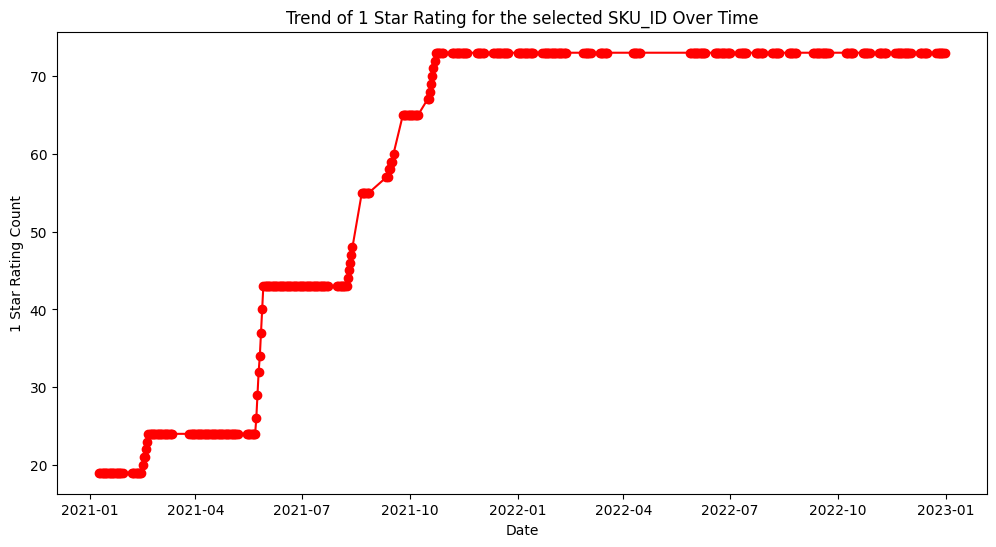

In [26]:
# Filter the data for SKU_ID of your choice
sku_level_data = product[product['SKU_ID'] == 'SKU1410']

# Plotting the trend of 1_Star_Rating for SKU1011 against the Date
plt.figure(figsize=(12, 6))
plt.plot(sku_level_data['Date'], sku_level_data['1_Star_Rating'], color='red', marker='o', linestyle='-')
plt.title("Trend of 1 Star Rating for the selected SKU_ID Over Time")
plt.xlabel("Date")
plt.ylabel("1 Star Rating Count")

plt.show()

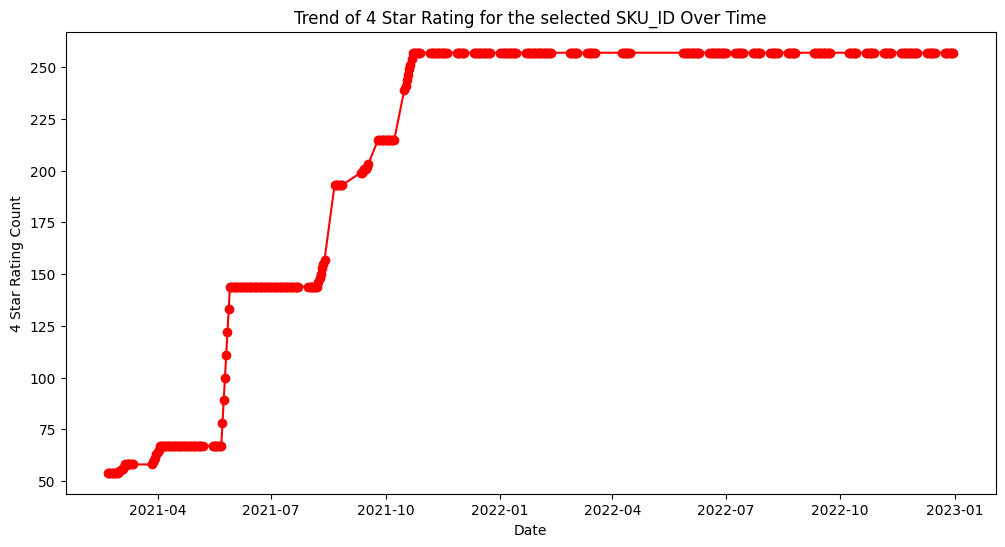

In [29]:
# Filter the data for SKU_ID of your choice
sku_level_data = product[product['SKU_ID'] == 'SKU1410']

# Plotting the trend of 1_Star_Rating for SKU1011 against the Date
plt.figure(figsize=(12, 6))
plt.plot(sku_level_data['Date'], sku_level_data['4_Star_Rating'], color='red', marker='o', linestyle='-')
plt.title("Trend of 4 Star Rating for the selected SKU_ID Over Time")
plt.xlabel("Date")
plt.ylabel("4 Star Rating Count")

plt.show()

## The Solution: Use Max()  

Q: Why Maximum?  

Daily data (cumulative ratings):  
Mon: 10 total ratings  
Tue: 12 total ratings  ← 2 more came in  
Wed: 12 total ratings  ← no change  
Thu: 15 total ratings  ← 3 more came in  
Fri: 15 total ratings  
Sat: 15 total ratings  ← THIS is the true total for the week  

Weekly aggregate:  
Sat: 15 total ratings  ← max() captures the final cumulative value  

8. Define Columns to Aggregate

In [30]:
#get the column names from product table to be aggregated at a weekly level
product.columns

Index(['SKU_ID', 'Date', '1_Star_Rating', '2_Star_Rating', '3_Star_Rating',
       '4_Star_Rating', '5_Star_Rating', 'Product_availability', 'Image_Count',
       'Bullet_Count', 'Title_Count', 'Description_Length', 'weekday',
       'weekend_date'],
      dtype='object')

In [31]:
#separate the column that needs to be aggregated
cols = ['1_Star_Rating', '2_Star_Rating', '3_Star_Rating',
       '4_Star_Rating', '5_Star_Rating', 'Image_Count',
       'Bullet_Count', 'Title_Count', 'Description_Length']

9. Group by Week and Take Maximum
- Groups all daily rows by (Saturday date, SKU_ID)
- Takes the maximum value for each group
- Result: One row per SKU per week  

Before (daily):  
SKU1011 | Mon | Jan 3 | 1_Star: 10  
SKU1011 | Tue | Jan 4 | 1_Star: 12  
SKU1011 | Wed | Jan 5 | 1_Star: 15  
...  

After (weekly):  
SKU1011 | Sat | Jan 8 | 1_Star: 15  ← Max for that week  

In [32]:
#grouping the product data, first by 'weekend_date' and then by 'SKU_ID' and taking the maximum value for each week and SKU ID for all columns in col
product_agg = product.groupby(['weekend_date','SKU_ID'])[cols].max().reset_index()

In [33]:
#checking the new dataframe
product_agg.head()

,weekend_date,SKU_ID,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,Title_Count,Description_Length
0,2021-01-02,SKU1011,29.0,21.0,49.0,99.0,694.0,5,5,91,59
1,2021-01-02,SKU1014,46.0,22.0,42.0,77.0,409.0,0,5,79,99
2,2021-01-02,SKU1024,21.0,15.0,39.0,93.0,782.0,0,8,163,158
3,2021-01-02,SKU1025,28.0,7.0,45.0,102.0,786.0,2,6,90,62
4,2021-01-02,SKU1036,58.0,24.0,71.0,166.0,1239.0,12,8,126,221


In [34]:
#get the shape of the product_agg dataframe
product_agg.shape

(21915, 11)

## Merge POS + Product
10. Merge the Datasets  
__Merge Logic__
- how='left' → Keep all POS rows, add Product info where available
- Match on: __Date__ (from POS) = __weekend_date__ (from Product) AND __SKU_ID__

In [35]:
#merging the product data and pos data
data = pd.merge(pos, product_agg, 
                how='left',
                left_on=['Date', 'SKU_ID'],
                right_on=['weekend_date', 'SKU_ID'])
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,weekday,weekend_date,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,Title_Count,Description_Length
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,5,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,5,2021-01-09,52.0,28.0,68.0,158.0,984.0,12.0,5.0,85.0,58.0
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,5,2021-01-16,53.0,29.0,72.0,166.0,1022.0,12.0,5.0,85.0,58.0
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,5,2021-01-23,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,5,2021-01-30,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0


11. Clean Up

In [36]:
#dropping the weekday and weekend variables since the data is already captured in 'Date'
data = data.drop(['weekday', 'weekend_date'], axis = 1)
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,Title_Count,Description_Length
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,52.0,28.0,68.0,158.0,984.0,12.0,5.0,85.0,58.0
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,166.0,1022.0,12.0,5.0,85.0,58.0
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0


In [37]:
#check the shape of data
data.shape # Now has POS columns + Product columns

(31185, 16)

# Video 4 - Combining all the tables in the Dataframe

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

## Dataset 1: Search Rank Data

In [38]:
#reading Search_Rank_Data and using parse_dates to interpret Date column as dates
search = pd.read_excel("DataSets/Search_Rank_Data.xlsx", parse_dates=['Date'])
search.head()

,SKU_ID,Date,num_unique_Search_Terms,Organic Search Rank
0,SKU1009,2021-01-02,7,13.0
1,SKU1009,2021-01-09,8,22.0
2,SKU1009,2021-01-16,8,25.0
3,SKU1009,2021-01-23,8,15.0
4,SKU1009,2021-01-30,8,18.0


In [39]:
#get a summary of all numerical variables of the search table
search.describe()
#search.shape

,Date,num_unique_Search_Terms,Organic Search Rank
count,25711,25711.000000,25711.000000
mean,2021-12-30 11:33:55.720119808,5.193186,19.025009
min,2021-01-02 00:00:00,1.000000,3.000000
25%,2021-06-26 00:00:00,3.000000,9.000000
50%,2022-01-01 00:00:00,5.000000,18.000000
75%,2022-07-02 00:00:00,7.000000,27.000000
max,2022-12-31 00:00:00,19.000000,53.000000
std,NaN,3.052156,11.679961


In [40]:
#get a summary of all categorical variables of the search table
search.describe(include = 'O')

,SKU_ID
count,25711
unique,295
top,SKU1009
freq,105


### Observations from search dataframe
1. 295 SKU_IDs (2 products missing!) in search data as compared to 297 SKU_IDs in pos data.

2. Looking at the date column in search.head(), it seems like the data is at week level. We will verify this.

3. Just like pos data, the search data also begins from 2nd Jan 2021 and goes on till 31st Dec 2022.

4. 25,711 records (less than POS's 31,185). This suggests that not all products have a record for every week.

## Find Missing Products

data_set:    {SKU1, SKU2, SKU3, SKU780, SKU952}  ← 297 products  
search_set:  {SKU1, SKU2, SKU3}                  ← 295 products  

__Step 1: Intersection__  
data_set.intersection(search_set) = {SKU1, SKU2, SKU3}  ← Common products  

__Step 2: Difference__  
data_set - intersection = {SKU780, SKU952}  ← Products missing from search!  

In [41]:
#creating sets for SKU_IDs for both the data and search dataframe
data_set = set(data.SKU_ID.values)
search_set = set(search.SKU_ID.values)

In [42]:
#finding the SKU_IDs not in search dataframe
data_set - data_set.intersection(search_set)

{'SKU780', 'SKU952'}

'SKU780', and 'SKU952' are the 2 SKU_IDs that are not there in the search dataframe. This could mean eihter we do not have data for these 2 products or any activity related to search ranking for these 2 products did not happen. Ideally we would need to talk to the team and investigate this matter further. 

In [43]:
#extract the day of the week
search['Date'].dt.dayofweek.value_counts()
# All are Saturdays (5) ✓

Date
5    25711
Name: count, dtype: int64

**Summary:** Keep all rows from `data`, and add the search metric columns from `search` where **Date** and **SKU_ID** match. If no match, fill with NaN.

---

## 📋 Visual Example of Left Join

### **BEFORE MERGE:**

**📊 data (left dataframe):**

| Date       | SKU_ID | Revenue | Page_traffic |
|------------|--------|---------|--------------|
| 2021-01-02 | SKU1   | 1000    | 500          |
| 2021-01-02 | SKU780 | 2000    | 600          |
| 2021-01-09 | SKU1   | 1200    | 550          |

**🔍 search (right dataframe):**

| Date       | SKU_ID | Search_Rank | Search_Clicks |
|------------|--------|-------------|---------------|
| 2021-01-02 | SKU1   | 5           | 100           |
| 2021-01-09 | SKU1   | 3           | 150           |

⚠️ **Note:** SKU780 is NOT in search dataset!

---

### **AFTER MERGE:** `pd.merge(data, search, how='left', on=['Date','SKU_ID'])`

**🔗 Combined Result:**

| Date       | SKU_ID | Revenue | Page_traffic | Search_Rank | Search_Clicks | Match Status |
|------------|--------|---------|--------------|-------------|---------------|--------------|
| 2021-01-02 | SKU1   | 1000    | 500          | 5           | 100           | ✅ Matched   |
| 2021-01-02 | SKU780 | 2000    | 600          | NaN         | NaN           | ❌ No match  |
| 2021-01-09 | SKU1   | 1200    | 550          | 3           | 150           | ✅ Matched   |

In [44]:
# The data is at a weekly level. Let's merge it with the data based on 'Dates' and 'SKU_ID'
data = pd.merge(data, search, how='left',on=['Date','SKU_ID'])
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,13.0
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,52.0,28.0,68.0,158.0,984.0,12.0,5.0,85.0,58.0,8.0,22.0
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,166.0,1022.0,12.0,5.0,85.0,58.0,8.0,25.0
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0,8.0,15.0
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0,8.0,18.0


In [45]:
#check the shape
data.shape

(31185, 18)

## Dataset 2: VPC Data (Variable Promo Coupons)

In [46]:
#reading the 'VPC_Data'and using parse_dates to interpret Date column as dates
vpc = pd.read_excel("DataSets/VPC_Data.xlsx",parse_dates=['Date'])
vpc.head()

,SKU_ID,Date,Num_of_Promotions,Variable Spend on Promotion,Sum of Spend
0,SKU1009,2021-11-06,1,430,1071.309703
1,SKU1009,2021-11-13,1,348,860.905508
2,SKU1009,2021-11-20,1,291,714.049918
3,SKU1009,2021-11-27,1,143,325.593408
4,SKU1009,2022-03-05,1,29,79.058869


In [47]:
#getting a summary of numerical variables
vpc.describe()

,Date,Num_of_Promotions,Variable Spend on Promotion,Sum of Spend
count,3194,3194.000000,3194.000000,3194.000000
mean,2021-10-08 10:19:27.689417472,1.014402,160.808078,407.362038
min,2021-01-02 00:00:00,1.000000,0.000000,0.000000
25%,2021-05-01 00:00:00,1.000000,46.000000,123.256904
50%,2021-08-28 00:00:00,1.000000,97.000000,252.476836
75%,2022-03-19 00:00:00,1.000000,223.000000,567.022259
max,2022-08-27 00:00:00,2.000000,1110.000000,2689.728363
std,NaN,0.119160,167.875977,414.741065


In [48]:
#getting a summary of categorical variables
vpc.describe(include = 'O')

,SKU_ID
count,3194
unique,260
top,SKU852
freq,49


### Observations from vpc dataframe
1. ✅ 260 SKU_IDs in vpc data as compared to 297 SKU_IDs in pos data (37 products don't have coupons).
2. ⚠️ Data only until Aug 27, 2022 (not full 2 years)
3. ⚠️ Data spread across the week (not just Saturdays)
4. We already have the sum of spend which is the total amount spent on promotions. 'Variable Spend on Promotion' is already a part of 'Sum of Spend' and hence it is not required.
5. For a specific date the max number of promotions is 2 and the min is 1.

In [49]:
#drop the Variable Spend on Promotion column
vpc = vpc.drop(["Variable Spend on Promotion"], axis = 1)

In [50]:
#creating sets for SKU_IDs for both the data and vpc dataframe
data_set = set(data.SKU_ID.values)
vpc_set = set(vpc.SKU_ID.values)

In [51]:
#finding the SKU_IDs not in vpc dataframe
data_set - vpc_set

{'SKU119',
 'SKU1208',
 'SKU1213',
 'SKU1220',
 'SKU1305',
 'SKU1416',
 'SKU1474',
 'SKU1544',
 'SKU1553',
 'SKU1651',
 'SKU1715',
 'SKU1776',
 'SKU1825',
 'SKU1924',
 'SKU1930',
 'SKU199',
 'SKU25',
 'SKU267',
 'SKU289',
 'SKU293',
 'SKU305',
 'SKU373',
 'SKU389',
 'SKU54',
 'SKU541',
 'SKU581',
 'SKU605',
 'SKU649',
 'SKU754',
 'SKU762',
 'SKU78',
 'SKU780',
 'SKU821',
 'SKU853',
 'SKU891',
 'SKU930',
 'SKU957'}

In [52]:
# checking the day of the week for week column
vpc['Date'].dt.dayofweek.value_counts()

Date
5    3194
Name: count, dtype: int64

In [53]:
#merging with the main data
data = pd.merge(data,vpc,how='left',on=['SKU_ID','Date'])
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank,Num_of_Promotions,Sum of Spend
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,13.0,NaN,NaN
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,52.0,28.0,68.0,158.0,984.0,12.0,5.0,85.0,58.0,8.0,22.0,NaN,NaN
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,166.0,1022.0,12.0,5.0,85.0,58.0,8.0,25.0,NaN,NaN
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0,8.0,15.0,NaN,NaN
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,169.0,1040.0,12.0,5.0,85.0,58.0,8.0,18.0,NaN,NaN


In [54]:
data.shape

(31185, 20)

## Dataset 3: Online Marketing Data


In [55]:
#reading online data and using parse_dates to interpret Date column as dates
online=pd.read_excel("DataSets/Online_Data.xlsx",parse_dates=['Date'])
online.head()

,SKU_ID,Date,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns
0,SKU1009,2021-05-15,474,1678.909243,53917,2
1,SKU1009,2021-06-12,1093,7198.857206,178173,2
2,SKU1009,2021-07-24,1041,5606.850110,224078,2
3,SKU1009,2021-07-31,965,4189.187114,191202,2
4,SKU1009,2021-08-07,860,2890.776596,212875,2


In [56]:
#getting the summary of the numerical variables
online.describe()

,Date,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns
count,10152,10152.000000,10152.000000,10152.000000,10152.000000
mean,2022-02-26 13:49:04.680850944,877.809496,3003.103046,159665.350473,3.105004
min,2021-01-02 00:00:00,372.000000,918.221774,49971.000000,2.000000
25%,2021-10-16 00:00:00,609.000000,1824.467267,93239.000000,2.000000
50%,2022-03-19 00:00:00,791.500000,2655.097905,134674.000000,2.000000
75%,2022-08-06 00:00:00,1069.000000,3655.659412,196578.000000,4.000000
max,2022-12-31 00:00:00,2774.000000,14766.997351,830774.000000,10.000000
std,NaN,369.477510,1703.249376,95716.397595,1.326884


In [57]:
#getting the summary of the categorical variables
online.describe(include = 'O')

,SKU_ID
count,10152
unique,249
top,SKU800
freq,97


### Observations from online dataframe
1. ✅ 249 SKU_IDs have online marketing (48 products don't)
2. ✅ Covers full 2 years (like POS data)

In [58]:
#creating sets for SKU_IDs for both the data and online dataframe
data_set = set(data.SKU_ID.values)
online_set = set(online.SKU_ID.values)

In [59]:
#finding the SKU_IDs not in online dataframe
data_set - online_set

{'SKU1053',
 'SKU1054',
 'SKU1061',
 'SKU109',
 'SKU1130',
 'SKU114',
 'SKU1183',
 'SKU1208',
 'SKU1215',
 'SKU1243',
 'SKU1278',
 'SKU1290',
 'SKU1305',
 'SKU1317',
 'SKU1332',
 'SKU1447',
 'SKU146',
 'SKU1495',
 'SKU1531',
 'SKU154',
 'SKU1546',
 'SKU1578',
 'SKU158',
 'SKU1581',
 'SKU1598',
 'SKU1625',
 'SKU1723',
 'SKU1755',
 'SKU176',
 'SKU1807',
 'SKU1954',
 'SKU1990',
 'SKU249',
 'SKU265',
 'SKU289',
 'SKU420',
 'SKU731',
 'SKU762',
 'SKU780',
 'SKU818',
 'SKU83',
 'SKU853',
 'SKU891',
 'SKU937',
 'SKU939',
 'SKU968',
 'SKU989',
 'SKU991'}

In [60]:
#checking if the data is at a weekly level saturday
online['Date'].dt.dayofweek.value_counts()

Date
5    10152
Name: count, dtype: int64

In [61]:
#merging online 'dataframe' with the 'data' dataframe
data= pd.merge(data,online,how='left',on=['SKU_ID','Date'])
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,7.0,13.0,NaN,NaN,NaN,NaN,NaN,NaN
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,52.0,28.0,68.0,...,85.0,58.0,8.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,85.0,58.0,8.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,85.0,58.0,8.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,85.0,58.0,8.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
# Filter for SKU1009 and date range
filtered_data = data[(data['SKU_ID'] == 'SKU1009') & 
                     (data['Date'] >= '2021-05-01') & 
                     (data['Date'] <= '2021-09-30')]
filtered_data

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns
17,SKU1009,2021-05-01,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,9.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN
18,SKU1009,2021-05-08,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,8.0,26.0,NaN,NaN,NaN,NaN,NaN,NaN
19,SKU1009,2021-05-15,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,7.0,19.0,NaN,NaN,474.0,1678.909243,53917.0,2.0
20,SKU1009,2021-05-22,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,8.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN
21,SKU1009,2021-05-29,0.0,0,NaN,0,Makeup,64.0,40.0,101.0,...,85.0,58.0,4.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN
22,SKU1009,2021-06-05,0.0,0,NaN,0,Makeup,64.0,40.0,101.0,...,85.0,58.0,8.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN
23,SKU1009,2021-06-12,0.0,0,NaN,0,Makeup,65.0,40.0,101.0,...,85.0,58.0,8.0,21.0,NaN,NaN,1093.0,7198.857206,178173.0,2.0
24,SKU1009,2021-06-19,0.0,0,NaN,0,Makeup,74.0,44.0,112.0,...,85.0,58.0,10.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN
25,SKU1009,2021-06-26,0.0,0,NaN,0,Makeup,76.0,45.0,114.0,...,85.0,58.0,8.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN
26,SKU1009,2021-07-03,0.0,0,NaN,0,Makeup,76.0,45.0,114.0,...,85.0,58.0,6.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
#check the shape of the data
data.shape

(31185, 24)

## Dataset 4: Offline Marketing Data

In [64]:
#reading the 'Offline_Data' and using parse_dates to interpret Date column as dates
offline=pd.read_excel("DataSets/Offline_Data.xlsx",parse_dates=['Date'])
offline.head()

,Country,Brand,Date,Clicks_image,Clicks_video,Cost_image,Cost_video,Impressions_image,Impressions_video,num_unique_campaigns
0,Country,Brand,2021-07-24,1989.0,6375,22497.13,77040.81,1549175.0,7539723,2
1,Country,Brand,2021-07-31,1989.0,6375,22497.13,77040.81,1549175.0,7539723,2
2,Country,Brand,2021-08-07,1848.0,5812,22527.47,70287.25,1518866.0,7108033,2
3,Country,Brand,2021-08-14,2614.0,9880,25734.03,102695.19,2035637.0,8531176,4
4,Country,Brand,2021-08-21,1989.0,6375,22497.13,77040.81,1549175.0,7539723,2


In [65]:
#getting the summary of numerical variables of the data 
offline.describe()
#offline.info()
#offline.isnull().sum()

,Date,Clicks_image,Clicks_video,Cost_image,Cost_video,Impressions_image,Impressions_video,num_unique_campaigns
count,38,25.000000,38.000000,25.000000,38.000000,2.500000e+01,3.800000e+01,38.000000
mean,2021-12-10 10:44:12.631578880,1857.240000,6480.263158,20573.035600,74695.607368,1.619379e+06,6.907338e+06,2.894737
min,2021-07-24 00:00:00,0.000000,3219.000000,0.000000,40244.280000,0.000000e+00,3.856872e+06,2.000000
25%,2021-09-26 18:00:00,1446.000000,4938.000000,20314.380000,57575.980000,1.473192e+06,5.547651e+06,2.000000
50%,2021-11-30 12:00:00,1989.000000,5744.000000,22527.470000,63978.200000,1.549175e+06,6.594469e+06,2.000000
75%,2022-02-24 06:00:00,2614.000000,7049.750000,25734.030000,83703.337500,2.035637e+06,7.539723e+06,4.000000
max,2022-04-30 00:00:00,3425.000000,11557.000000,34273.050000,130779.050000,3.469776e+06,1.092277e+07,6.000000
std,NaN,936.071546,2437.052115,9042.155713,24819.709951,8.293666e+05,1.824577e+06,1.448008


In [66]:
#getting the summary of categorical variables of the data 
offline.describe(include = 'O')

,Country,Brand
count,38,38
unique,1,1
top,Country,Brand
freq,38,38


### Observations from online dataframe
1.⚠️ Brand-level data (not SKU_ID level!)  
2. ⚠️ Only 38 weeks have offline campaigns (not continuous)  
3. ❌ Country & Brand: only 1 value (useless)  
4. ❌ Image columns: many nulls (25/38 dates only -- look at 'count' row)  
5. ⚠️ num_unique_campaigns conflicts with online column name  


In [67]:
#dropping "Country", "Brand", "Clicks_image", "Cost_image", "Impressions_image"
offline = offline.drop(["Country", "Brand", "Clicks_image", "Cost_image", "Impressions_image"], axis = 1)

In [68]:
#rename num_unique_campaigns as it is the same as the one in online campaign
offline.rename(columns={'num_unique_campaigns': 'num_unique_campaigns_offline'}, inplace=True)

In [69]:
#check offline data
offline.head()

,Date,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,2021-07-24,6375,77040.81,7539723,2
1,2021-07-31,6375,77040.81,7539723,2
2,2021-08-07,5812,70287.25,7108033,2
3,2021-08-14,9880,102695.19,8531176,4
4,2021-08-21,6375,77040.81,7539723,2


In [70]:
#check the date column to see if the dates belong to a saturday
offline['Date'].dt.dayofweek.value_counts()

Date
5    38
Name: count, dtype: int64

In [71]:
#merging online 'offline' with the 'data' dataframe
data = pd.merge(data,offline,how='left',on='Date')
data.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,SKU1009,2021-01-02,0.0,0,NaN,0,Makeup,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SKU1009,2021-01-09,0.0,0,NaN,0,Makeup,52.0,28.0,68.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SKU1009,2021-01-16,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SKU1009,2021-01-23,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,SKU1009,2021-01-30,0.0,0,NaN,0,Makeup,53.0,29.0,72.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [72]:
#checking the shape of the data
data.shape

(31185, 28)

# Video 5 - Understanding the Combined Data

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

In [73]:
#checking the variable types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31185 entries, 0 to 31184
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   SKU_ID                        31185 non-null  object        
 1   Date                          31185 non-null  datetime64[ns]
 2   Page_traffic                  31185 non-null  float64       
 3   Revenue($)                    31185 non-null  int64         
 4   Unit_price                    19635 non-null  float64       
 5   Units_sold                    31185 non-null  int64         
 6   Segment                       31185 non-null  object        
 7   1_Star_Rating                 18967 non-null  float64       
 8   2_Star_Rating                 18750 non-null  float64       
 9   3_Star_Rating                 18748 non-null  float64       
 10  4_Star_Rating                 18697 non-null  float64       
 11  5_Star_Rating               

## Observations from the combined data

Total Columns: 28
- SKU_ID, Date, Segment → Categorical
- Rest → Continuous numerical

Column Counts (Non-Null):  
✅ 31,185: SKU_ID, Date, Page_traffic, Revenue, Units_sold, Segment  
⚠️ 19,635: Unit_price (11k missing!)  
⚠️ 18,619-18,967: Star Ratings (product attributes)  
⚠️ 25,711: Search data  
⚠️ 3,194: VPC/Promotions (sparse!)  
⚠️ 10,152: Online marketing  
⚠️ Few: Offline campaigns  

## Phase 2: Identify Target Variable

__Choose Dependent Variable__ (Dependent Variable = What you want to PREDICT)

Two Options:  
- Revenue($)
- Units_sold  

__Decision__: Use Units_sold as target variable  
Business Question: "How many units will we sell next week?"  
Dependent Variable: **Units_sold**

In [74]:
#getting a summary of 'data' dataframe
data.describe()

,Date,Page_traffic,Revenue($),Unit_price,Units_sold,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
count,31185,31185.000000,31185.000000,19635.000000,31185.000000,18967.000000,18750.000000,18748.000000,18697.000000,18619.000000,...,3194.000000,3194.000000,10152.000000,10152.000000,10152.000000,10152.000000,11286.000000,11286.000000,1.128600e+04,11286.000000
mean,2021-12-31 23:59:59.999999744,2053.829695,14386.877505,22.038169,702.274363,75.447936,53.615680,145.289258,295.620581,1941.743004,...,1.014402,407.362038,877.809496,3003.103046,159665.350473,3.105004,6480.263158,74695.607368,6.907338e+06,2.894737
min,2021-01-02 00:00:00,0.000000,0.000000,0.103030,0.000000,10.000000,7.000000,16.000000,31.000000,153.000000,...,1.000000,0.000000,372.000000,918.221774,49971.000000,2.000000,3219.000000,40244.280000,3.856872e+06,2.000000
25%,2021-07-03 00:00:00,0.000000,0.000000,16.311504,0.000000,40.000000,29.000000,76.000000,153.000000,998.000000,...,1.000000,123.256904,609.000000,1824.467267,93239.000000,2.000000,4791.000000,56344.760000,5.344861e+06,2.000000
50%,2022-01-01 00:00:00,1963.000000,14952.000000,20.746141,765.000000,68.000000,49.000000,130.000000,262.000000,1707.000000,...,1.000000,252.476836,791.500000,2655.097905,134674.000000,2.000000,5744.000000,63978.200000,6.594469e+06,2.000000
75%,2022-07-02 00:00:00,3647.000000,25670.000000,25.423036,1224.000000,99.000000,71.000000,193.000000,393.000000,2611.000000,...,1.000000,567.022259,1069.000000,3655.659412,196578.000000,4.000000,7236.000000,83933.100000,7.539723e+06,4.000000
max,2022-12-31 00:00:00,10696.000000,48572.000000,94.133971,3386.000000,337.000000,240.000000,679.000000,1418.000000,9707.000000,...,2.000000,2689.728363,2774.000000,14766.997351,830774.000000,10.000000,11557.000000,130779.050000,1.092277e+07,6.000000
std,NaN,1979.574340,13427.614446,9.849729,647.676402,46.155850,32.488329,91.029103,187.916058,1270.881736,...,0.119160,414.741065,369.477510,1703.249376,95716.397595,1.326884,2404.878398,24492.042642,1.800489e+06,1.428892


## Visualize Distribution

4. Visualize with Zeros

<Axes: >

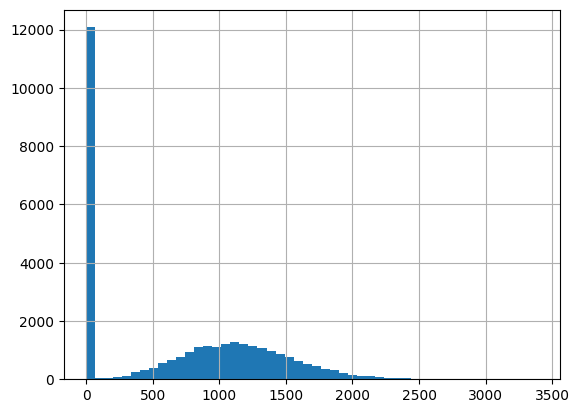

In [75]:
#visualise Untis_sold with a histogram
data['Units_sold'].hist(bins = 50)

5. Visualize without Zeros

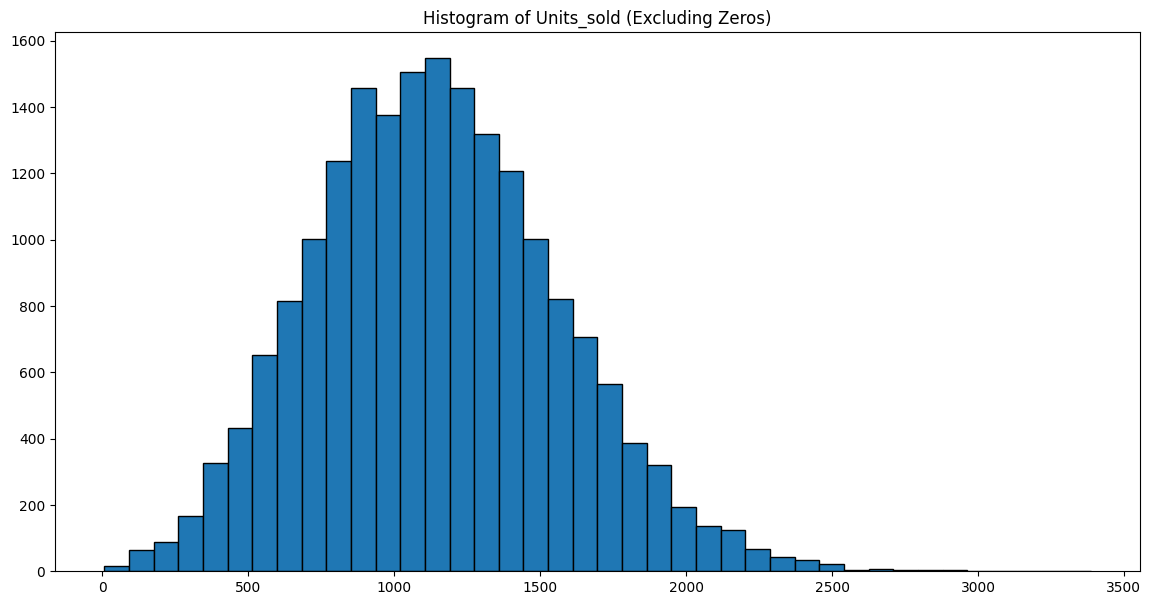

In [76]:
# Filter out the rows where 'Units_sold' is zero
filtered_data = data[data['Units_sold'] > 0]

# Create a histogram for 'Units_sold' without zeros, with 50 bins
plt.figure(figsize=(14, 7))
plt.hist(filtered_data['Units_sold'], bins=40, edgecolor='black')
plt.title('Histogram of Units_sold (Excluding Zeros)')
plt.show()

## Phase: Investigate Anomalies

**Notes**  
- Positive Correlation (+1) - Both variables increase together (Ex. More traffic = More sales) 
- Negative Correlation (-1) - One increases, the other decreases (Ex. Higher price = Fewer sales)
- No Correlation (0) - No relationship between variables

6. Check Correlation -- "Do more page views lead to more sales?"

In [77]:
#check correlation between 'Units_sold' and 'Page_traffic'
data['Page_traffic'].corr(data['Units_sold'])

np.float64(0.8644533046153509)

In [78]:
#check the cases where 'Page_traffic' for a product is 0 and 'Units_sold' is greater than 0
data[(data['Page_traffic'] == 0) & (data['Units_sold']>0)]

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline


## Phase: Create Focused Dataset

8. Filter Out Zero Page Traffic (Filter out product page that nobody went)

In [79]:
# Checking the values where Page_traffic > 0 and assigning this dataframe to a new variable - 'data_focus'
data_focus  = data[data['Page_traffic']>0]
data_focus.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
105,SKU1011,2021-01-02,4119.0,4650,6.671449,697,Makeup,29.0,21.0,49.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
106,SKU1011,2021-01-09,4074.0,11435,11.134372,1027,Makeup,36.0,28.0,62.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
107,SKU1011,2021-01-16,4897.0,11603,11.189007,1037,Makeup,38.0,30.0,64.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
108,SKU1011,2021-01-23,4783.0,14067,11.880912,1184,Makeup,38.0,30.0,64.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
109,SKU1011,2021-01-30,3789.0,6188,7.063927,876,Makeup,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [80]:
#Checking the shape of data_focus
data_focus.shape

(19631, 28)

In [82]:
data_focus.describe().transpose()

,count,mean,min,25%,50%,75%,max,std
Date,19631,2021-12-31 04:00:00.733533696,2021-01-02 00:00:00,2021-06-26 00:00:00,2022-01-01 00:00:00,2022-07-02 00:00:00,2022-12-31 00:00:00,NaN
Page_traffic,19631.0,3262.629466,5.0,2207.0,3275.0,4249.0,10696.0,1510.350882
Revenue($),19631.0,22854.402476,0.0,16483.5,23098.0,29767.0,48572.0,9638.143686
Unit_price,19235.0,21.491858,0.10303,16.339797,20.700226,25.280734,94.133971,7.845159
Units_sold,19631.0,1115.604197,0.0,825.0,1114.0,1410.0,3386.0,453.048322
1_Star_Rating,12020.0,75.057404,10.0,40.0,68.0,98.0,301.0,44.834974
2_Star_Rating,11889.0,53.646396,7.0,29.0,49.0,71.0,197.0,31.602739
3_Star_Rating,11919.0,144.399278,16.0,75.0,130.0,192.0,557.0,88.950386
4_Star_Rating,11832.0,295.551809,31.0,156.0,261.0,392.0,1180.0,182.9261
5_Star_Rating,11762.0,1941.880292,153.0,1036.0,1701.0,2610.75,7950.0,1230.135878


In [83]:
data.describe(include = 'O')

,SKU_ID,Segment
count,31185,31185
unique,297,3
top,SKU1009,Makeup
freq,105,17220


# Video 6 - Treating Missing Values

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

__data_focus__ - Filtered dataset with Page_traffic > 0

__Goal__: Handlea all missing values using appropriate strategies

## Phase 1: Identify Missing Values

1. Check Missing Value Counts  

0 = No Missing Values (✅ Complete data - perfect!)  
Positive Number = Count of rows that has Missing Values (❌ Incomplete data - needs fixing!)  

Ex.  
✅ All 30,000 rows have SKU_ID and etc..  
❌ 396 rows missing unit price

In [ ]:
#check the missing values Counts
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                        396
Units_sold                          0
Segment                             0
1_Star_Rating                    7611
2_Star_Rating                    7742
3_Star_Rating                    7712
4_Star_Rating                    7799
5_Star_Rating                    7869
Image_Count                      5840
Bullet_Count                     5840
Title_Count                      5840
Description_Length               5840
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

## Phase 2: Analyze Unit_price Missing Pattern

2. Find Which Products Have Missing Prices

In [ ]:
#find the SKU_IDs where Unit_price has null values throughout a particular SKU_ID 
a = data_focus[data_focus['Unit_price'].isnull()]['SKU_ID'].unique()
print (a) 
# Return 52 products that have missing prices

['SKU1014' 'SKU1053' 'SKU106' 'SKU1066' 'SKU1067' 'SKU1072' 'SKU1086'
 'SKU1092' 'SKU118' 'SKU1183' 'SKU123' 'SKU1237' 'SKU1245' 'SKU1270'
 'SKU1317' 'SKU1332' 'SKU1458' 'SKU1459' 'SKU1510' 'SKU1531' 'SKU1546'
 'SKU1597' 'SKU1598' 'SKU1625' 'SKU1628' 'SKU1651' 'SKU1719' 'SKU1723'
 'SKU1733' 'SKU1763' 'SKU183' 'SKU1834' 'SKU1911' 'SKU1954' 'SKU1990'
 'SKU225' 'SKU234' 'SKU257' 'SKU278' 'SKU289' 'SKU300' 'SKU305' 'SKU330'
 'SKU352' 'SKU675' 'SKU731' 'SKU761' 'SKU866' 'SKU930' 'SKU937' 'SKU968'
 'SKU989']


- __'a'__ contains 52 SKU_IDs that have at least one missing price  

Proportion = (Missing count) / (Total rows for that product)  

Ex.  
1. SKU1014 has:
- 50 total weeks of data
- 20 weeks missing price
- 30 weeks have price

Proportion = 20/50 = 0.4 (40% missing)

2. 
SKU1053 has:
- 50 total weeks of data
- 50 weeks missing price
- 0 weeks have price

Proportion = 50/50 = 1.0 (100% missing)

In [89]:
# Calculate proportion of missing values per SKU
for i in a:
    proportion = (data_focus[data_focus['SKU_ID']==i]['Unit_price'].isnull().sum() / 
                  data_focus[data_focus['SKU_ID']==i].shape[0])
    print(proportion)

1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0


__Result__: All print 1.0 → __100% missing for these 52 SKUs!__  
__Meaning__: These products have __NO price data at all__ across any week

## Decision Tree:  
- If proportion __<__ 1.0 (Some prices exist):
    - Can use product's own median/mean price to fill NaN
- If proportion __=__ 1.0 (ALL prices missing):
    - Use OTHER products (segment median)

## Strategy 1: Fill Unit_price with Segment Median

4. Impute Using Segment Median

In [90]:
# Fill missing prices with median price of same Segment
data_focus['Unit_price'] = data_focus.groupby('Segment')['Unit_price'].transform(
    lambda x: x.fillna(x.median())
)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\4031605351.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus['Unit_price'] = data_focus.groupby('Segment')['Unit_price'].transform(


In [91]:
#check the missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                    7611
2_Star_Rating                    7742
3_Star_Rating                    7712
4_Star_Rating                    7799
5_Star_Rating                    7869
Image_Count                      5840
Bullet_Count                     5840
Title_Count                      5840
Description_Length               5840
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

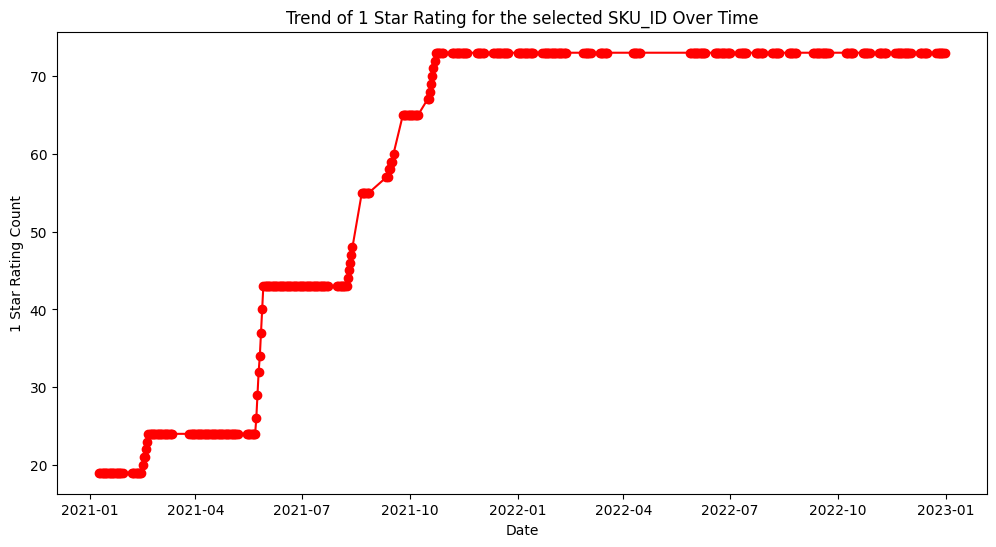

In [92]:
# Filter the data for SKU_ID of your choice
sku_level_data = product[product['SKU_ID'] == 'SKU1410']

# Plotting the trend of 1_Star_Rating for SKU1011 against the Date
plt.figure(figsize=(12, 6))
plt.plot(sku_level_data['Date'], sku_level_data['1_Star_Rating'], color='red', marker='o', linestyle='-')
plt.title("Trend of 1 Star Rating for the selected SKU_ID Over Time")
plt.xlabel("Date")
plt.ylabel("1 Star Rating Count")

plt.show()

## Strategy 2: Fill Star Ratings with Forward Fill

5. Forward Fill Ratings (Carry Forward Last Value)

In [96]:
#group the data by 'SKU_ID' and apply forward fill to fill the missing values in the specified columns
columns_to_fill = ['1_Star_Rating', '2_Star_Rating', '3_Star_Rating', '4_Star_Rating', '5_Star_Rating']

In [97]:
#apply the backfill operation within each SKU_ID group for the specified columns

data_focus[columns_to_fill] = data_focus.groupby('SKU_ID')[columns_to_fill].apply(
    lambda group: group.ffill()
).reset_index(level=0, drop=True)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\2789317269.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus[columns_to_fill] = data_focus.groupby('SKU_ID')[columns_to_fill].apply(


__Logic__:  
- Ratings are cumulative (total count over time)
- If rating is missing, use the last known value
- Makes sense: ratings usually don't disappear  

Ex.  
SKU1001, Week 1: 1_Star = 10  
SKU1001, Week 2: 1_Star = NaN  → Fill with 10 (forward fill)  
SKU1001, Week 3: 1_Star = 15  
SKU1001, Week 4: 1_Star = NaN  → Fill with 15 (forward fill)  

In [101]:
#check the missing values after backfill operation
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                      5840
Bullet_Count                     5840
Title_Count                      5840
Description_Length               5840
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

Since there still exist null values thus means there's no previous value to reference. Thus  

6. Fill Remaining with 0  

__Logic__: If no ratings exist at all → 0 (no reviews yet)

In [99]:
#fill the remaining null values in the rating columns with 0
data_focus[columns_to_fill] = data_focus[columns_to_fill].fillna(0)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\3096414107.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus[columns_to_fill] = data_focus[columns_to_fill].fillna(0)


In [102]:
#check the missing values
data_focus.isna().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                      5840
Bullet_Count                     5840
Title_Count                      5840
Description_Length               5840
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

## Strategy 3: Fill Product Attributes with Median

7. Fill Static Product Features  

Logic:
- These are static (don't change much over time)
- Use product's own median value
- Example: If SKU has 5 images usually, use 5 for missing weeks

In [104]:
#list of columns to fill with the median value within each SKU_ID group
columns_to_fill_with_median = ['Image_Count', 'Bullet_Count', 'Title_Count', 'Description_Length']

In [105]:
#compute the median for each column within each SKU_ID group and fill NA values with that median
for col in columns_to_fill_with_median:
    data_focus[col] = data_focus.groupby('SKU_ID')[col].transform(lambda x: x.fillna(x.median()))

C:\Users\ongja\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\ongja\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\ongja\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\3954361107.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_

In [106]:
#check the missing values
data_focus.isna().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         3
Bullet_Count                        3
Title_Count                         3
Description_Length                  3
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

8. Fill Remaining with Overall Median

In [107]:
# If still missing (product has NO data), use overall median
data_focus[columns_to_fill_with_median] = data_focus[columns_to_fill_with_median].fillna(data_focus[columns_to_fill_with_median].median())

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\1706246270.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus[columns_to_fill_with_median] = data_focus[columns_to_fill_with_median].fillna(data_focus[columns_to_fill_with_median].median())


In [108]:
#check missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms          3583
Organic Search Rank              3583
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

## 📋 Summary of Strategies:
| Column Type       | Strategy | Why  |
|------------|--------|-------------|
| Unit_price | Segment Median   | No product data -> Use similiar products   |
| Star Ratings | Forward fill -> 0   | Cumullative -> Carry forward last value           |
| Image/Bullet/Title | Product Own's Median -> Overall Median  | Static feature -> Use product's typical value           |
| Sparse Marketing | Leave as-is   | Missing = No campaign (meaningful)         |

**Note:** Sparse = Mostly empty/missing (60-90% of values are NaN)


# Video 7 - Treating Missing Values - Part 2

# Phase 1: Handle Search Ranking Data

1. Forward Fill Search Rank

In [110]:
# Fill Organic Search Rank by carrying forward last value
data_focus['Organic Search Rank'] = data_focus.groupby('SKU_ID')['Organic Search Rank'].apply(
    lambda group: group.ffill()
).reset_index(level=0, drop=True)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\2507252271.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus['Organic Search Rank'] = data_focus.groupby('SKU_ID')['Organic Search Rank'].apply(


In [111]:
#check missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms          3583
Organic Search Rank               587
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

In [112]:
# If still missing (new products), use segment median
data_focus['Organic Search Rank'] = data_focus.groupby('Segment')['Organic Search Rank'].transform(
    lambda x: x.fillna(x.median())
)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\1303988135.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus['Organic Search Rank'] = data_focus.groupby('Segment')['Organic Search Rank'].transform(


In [114]:
#check the missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms          3583
Organic Search Rank                 0
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

3. Fill Search Terms with 0  

Logic:
- Missing = No search activity
- 0 = Product wasn't searched for

In [115]:
# Fill num_unique_Search_Terms with 0
data_focus['num_unique_Search_Terms'] = data_focus['num_unique_Search_Terms'].fillna(0)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\1181147873.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus['num_unique_Search_Terms'] = data_focus['num_unique_Search_Terms'].fillna(0)


In [116]:
#check missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms             0
Organic Search Rank                 0
Num_of_Promotions               17565
Sum of Spend                    17565
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

## Phase 2: Handle Promotional Data (VPC Data)

4. Fill Promotion Columns with 0  

Logic:
- Missing = No promotion that week
- 0 is meaningful: "No spend, no promos"  
- Not a data quality issue!  

Ex.  
Week 1: Promotion = $500  ✅ (Had promotion)  
Week 2: Promotion = NaN   → Fill with 0 (No promotion)  
Week 3: Promotion = $300  ✅ (Had promotion)  
Week 4: Promotion = NaN   → Fill with 0 (No promotion)  

In [119]:
#create list with the name of the columns
columns_to_fill_2 = ['Sum of Spend', 'Num_of_Promotions']

#fill the missing values in the list with 0
data_focus[columns_to_fill_2] = data_focus[columns_to_fill_2].fillna(0)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\1921347036.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus[columns_to_fill_2] = data_focus[columns_to_fill_2].fillna(0)


In [118]:
#check missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms             0
Organic Search Rank                 0
Num_of_Promotions                   0
Sum of Spend                        0
Online_Clicks                   10035
Online_Cost                     10035
Online_Impressions              10035
num_unique_campaigns            10035
Clicks_video                    12550
Cost_video                      12550
Impressions_

## Phase 3: Handle One Marketing Data

5. Fill Online Campaign Columns with 0  

Logic:
- Missing = No online campaign that week
- 0 clicks, 0 cost, 0 impressions = No campaign
- Absence is meaningful!

In [121]:
#create a list with the column names to be imputed
columns_to_fill_3 = ['Online_Clicks', 'Online_Cost', 'Online_Impressions', 'num_unique_campaigns']

#impute the values with 0
data_focus[columns_to_fill_3] = data_focus[columns_to_fill_3].fillna(0)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\4285159772.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus[columns_to_fill_3] = data_focus[columns_to_fill_3].fillna(0)


In [122]:
#check missing values
data_focus.isnull().sum()

SKU_ID                              0
Date                                0
Page_traffic                        0
Revenue($)                          0
Unit_price                          0
Units_sold                          0
Segment                             0
1_Star_Rating                       0
2_Star_Rating                       0
3_Star_Rating                       0
4_Star_Rating                       0
5_Star_Rating                       0
Image_Count                         0
Bullet_Count                        0
Title_Count                         0
Description_Length                  0
num_unique_Search_Terms             0
Organic Search Rank                 0
Num_of_Promotions                   0
Sum of Spend                        0
Online_Clicks                       0
Online_Cost                         0
Online_Impressions                  0
num_unique_campaigns                0
Clicks_video                    12550
Cost_video                      12550
Impressions_

## Phase 4: Fill Any Remainng Missing Values

6. Final Cleanup - Fill All Remaining with 0  

Logic:
- Catch-all for any missed columns
- Most remaining nulls are marketing-related
- 0 = "No activity"

In [123]:
# Fill any remaining NaN with 0
data_focus.fillna(0, inplace=True)

C:\Users\ongja\AppData\Local\Temp\ipykernel_19892\1130901472.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_focus.fillna(0, inplace=True)


In [124]:
#check missing values
data_focus.isnull().sum()

SKU_ID                          0
Date                            0
Page_traffic                    0
Revenue($)                      0
Unit_price                      0
Units_sold                      0
Segment                         0
1_Star_Rating                   0
2_Star_Rating                   0
3_Star_Rating                   0
4_Star_Rating                   0
5_Star_Rating                   0
Image_Count                     0
Bullet_Count                    0
Title_Count                     0
Description_Length              0
num_unique_Search_Terms         0
Organic Search Rank             0
Num_of_Promotions               0
Sum of Spend                    0
Online_Clicks                   0
Online_Cost                     0
Online_Impressions              0
num_unique_campaigns            0
Clicks_video                    0
Cost_video                      0
Impressions_video               0
num_unique_campaigns_offline    0
dtype: int64

# Video 9 - Preparing the Dataset for classification, regression and unsupervised problems (Data Preparation)

**Goal**: Create different versions of the dataset for different types of machine learning tasks

🎯 Three Types of ML Problems:

| Type | Goal | Example |
|------|------|---------|
| Regression | Predict continous number | Predict Units_sold (10,50,100,....) |
| Classification | Predict category |  Predict if Units_sold > 1000 (Yes/No) |
| Un-supervised | Find patterns (no target) | Customer segmentation, clustering |


### Phase 1: Prepare for Unsupervised Learning Models  

1. Export Clean Data (No Target Variable)  

What's in it:
- All features (columns)
- No specific target variable needed
- Clean, no missing values
- Ready for clustering, PCA, etc.  

Use cases:  

- Customer segmentation
- Product clustering
- Anomaly detection

In [125]:
#exporting the dataframe to the specified path (saves in same folder as notebook)
file_path = 'Synergix_data_preprocessed_unsupervised_new.csv'
data_focus.to_csv(file_path, index=False)

### Phase 2: Prepare for Supervised Learning Models  

2. Shuffle the Data (randomly re-order the rows of dataset)  
Why shuffle?
- Data might be sorted by date or product
- ML models train better on randomized data
- Prevents learning spurious patterns from order
- frac=1 = use 100% of data (all rows)
- random_state=1 = reproducible shuffle

In [ ]:
# Shuffle rows randomly
data_final = data_focus.sample(frac=1, random_state=1)
data_final.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
11196,SKU1539,2022-04-09,5835.0,46006,22.214389,2071,Skincare,99.0,72.0,194.0,...,0.0,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0
8628,SKU1431,2021-05-08,1881.0,8084,11.870778,681,Skincare,118.0,73.0,200.0,...,0.0,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0
31078,SKU995,2022-12-24,2477.0,24190,27.645714,875,Makeup,108.0,85.0,232.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
3032,SKU1136,2022-10-08,4087.0,23588,16.896848,1396,Makeup,82.0,64.0,167.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
23269,SKU528,2022-03-26,1446.0,13446,16.357664,822,Hair Care,29.0,24.0,88.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0


In [127]:
#check the shape of the data
data_final.shape, data_focus.shape

((19631, 28), (19631, 28))

3. Create Classification Target Variable

**Why?**
- Classification models need categories (0/1, Yes/No)
- Regression predicts exact number (50, 500, 1200)
- Classification predicts category (High sales / Low sales)

In short:  
a. Regression → Use __Units_sold__ (continuous)  
b. Classification → Use __Units_sold>1000__ (binary)

In [128]:
# Create binary target: Did product sell > 1000 units?
data_final['Units_sold>1000'] = (data_final['Units_sold'] > 1000) * 1

Ex.  
Original Units_sold → New Classification Target  
50     → *0*  (No, *not* > 1000)  
500    → *0*  (No, *not* > 1000)  
1200   → **1**  (Yes, > 1000!)  
2000   → **1**  (Yes, > 1000!)  
800    → *0*  (No, *not* > 1000)

In [135]:
#check the dataframe for new column
data_final.columns

Index(['Page_traffic', 'Unit_price', 'Units_sold', 'Segment', '1_Star_Rating',
       '2_Star_Rating', '3_Star_Rating', '4_Star_Rating', '5_Star_Rating',
       'Image_Count', 'Bullet_Count', 'Title_Count', 'Description_Length',
       'num_unique_Search_Terms', 'Organic Search Rank', 'Num_of_Promotions',
       'Sum of Spend', 'Online_Clicks', 'Online_Cost', 'Online_Impressions',
       'num_unique_campaigns', 'Clicks_video', 'Cost_video',
       'Impressions_video', 'num_unique_campaigns_offline', 'Units_sold>1000'],
      dtype='object')

### 4. Removing irrelvant columns for ML

Three columns to consider removing:

| Column | Why Remove? | Impact |
|------|------|---------|
| Date | Time-series not needed (for now) | Can use later for feature engineering |
| SKU_ID | Just an ID, no predictive value |  Model can't learn from product IDs |
| Revenue($) | Already exist in Units_sold | Revenue = Units_sold × Unit_price (redundant!) |

## 📦 Create Different Dataset Versions:

Version 1: For Feature Engineering (*data_fe*)

In [ ]:
# Keep Date, remove SKU_ID and Revenue
data_fe = data_final.drop(['SKU_ID', 'Revenue($)'], axis=1)
data_fe.head()

,Date,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
11196,2022-04-09,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
8628,2021-05-08,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
31078,2022-12-24,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3032,2022-10-08,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
23269,2022-03-26,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


Use for:
- Feature engineering (extract month, week, season from Date)
- Time-based analysis
- Advanced ML models

In [131]:
#exporting the file to the specified location (saves in same folder as notebook)
file_path = 'Synergix_data_fe_new.csv'
data_fe.to_csv(file_path, index=False)

**Version 2: For Standard ML (*data_final*)**

In [ ]:
#deleting the irrelevant columns
data_final.drop(['Date', 'SKU_ID', 'Revenue($)'], axis=1, inplace=True)

In [136]:
data_final.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
11196,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
8628,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
31078,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3032,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
23269,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


Use for:
- Standard regression models
- Standard classification models
- General machine learning

In [137]:
#exporting the file to the specified location (saves in same folder as notebook)
file_path = 'Synergix_data_preprocessed_new.csv'
data_final.to_csv(file_path, index=False)

## 📊 Summary of Dataset Versions

| **Dataset** | **Purpose** | **Has Date?** | **Has SKU_ID?** | **Has Revenue?** | **Has Targets?** |
|------------|---------|---------------|---------|--------|--------------------|
| **data_focus** | Unsupervised | ✅ | ✅ | ✅ | ❌ No Target Needed |
| **data_fe** | Feature Engineering | ✅  | ❌ | ❌ | ✅ Both Targets
| **data_final** | Standard ML | ❌ | ❌ | ❌ | ✅ Both Targets |

## 🎯 Target Variables:  

**For Regression:**  
```python
# Predict exact number of units
target = 'Units_sold'

Examples:
- Predict: 50 units
- Predict: 1200 units
- Predict: 3500 units
``` 


**For Classification:**
```python
# Predict category (High/Low sales)
target = 'Units_sold>1000'

Examples:
- Predict: 0 (Low sales, ≤ 1000)
- Predict: 1 (High sales, > 1000)
``` 
